Follow the notebook to build basis change operator to change basis from y lattice to y subbands

In [102]:
from config import *

import Operators2D as Op

class twoD_Minimal_Model:

    def __init__(self, n, nsm, nsc, m, ax, ay, omega=1, alphat=0, delta=0, meff_sc=1, meff_sm = 1 , mu_sc = 0, mu_sm=0, dis_mean=0, dis_var=1, px=False, py=False,  epsilon=0):

        """
        Initializes a new instance of the oneD_Minimal_Model class.
        
        Args:
            n (int): The number of horizontal lattice points of the system.
            nsm (int): The number of horizontal lattice points of the semiconductor weak link.
            nsc (int): The number of horizontal lattice points of the superconductor on both sides.
            m (int): The number of vertical lattive points
            ax (float): The horizontal (x) lattice spacing.
            ay (float): The vertical (y) lattice spacing.
            meff (float): Effective mass 
            alphat (float): spin orbit coupling constant
            mu_s (float): chemical potential of the superconducting region of SNS
            mu_sm (float): chemical potential of the semiconductingconducting region of SNS
            px (bool, optional): Flag indicating periodicity in x direction. Defaults to False.
            epsilon (float): Kx^4 prefactor to remove higher k states from dipping

        Notes:
            - The ordering of lattice points for kx, kxsq, kxcu(imported for operator class file) is from left to right, bottom to top, similar to x and y axis in 2D g

        """

        self.n = n
        self.nsm = nsm
        self.nsc = nsc
        self.m = m
        self.ax = ax
        self.ay = ay
        self.omega = omega
        self.meff_sc = meff_sc
        self.meff_sm = meff_sm
        self.alphat = alphat
        self.delta = delta
        self.mu_sc = mu_sc
        self.mu_sm  = mu_sm
        self.dis_mean = dis_mean
        self.dis_var = dis_var
        self.px = px
        self.py = py
        self.epsilon = epsilon
        self.twodOP = Op.Operators_2d(self.n, self.m, self.ax, self.ay, self.px, self.py)

    def ysq_matrix(self):

        row = np.empty(0)
        col = np.empty(0)
        data = np.empty(0)

        shift = (((self.m//2))*self.ay)

        #print('SHIFT YSQ: ', shift )

        for j in range(self.m):

            for i in range(self.n):
            
                row = np.append(row, j*self.n + i)
                col = np.append(col, j*self.n + i)
                data = np.append(data, ((j)*self.ay-shift)**2)

        M = csr_matrix((data,(row,col)),shape=(self.m*self.n, self.m*self.n))

        return M

    def SHO_wvfn(self, ne, yj=0):

        """
        Return Phi__ne(yj) where yj is the jth index and ne is the quantum number of SHO wavefunction and the whole array
        """

        # define constant of SHo wavefunctions 

        kappa = self.omega/hbm*self.meff_sm
        normalization_const = 1/math.sqrt(2**ne * math.factorial(ne))*(kappa/2/math.pi)**(0.25)

        # Create the Hermite polynomial 
        coefficients = np.zeros(ne+1)
        coefficients[ne] = 1  # Setting the leading coefficient as per the physicist's definition
        
        H_n = Hermite(coefficients)

        shift = (((self.m//2))*self.ay) ### same shift from as the ysq_matrix 

        #print('SHIFT Y_array: ', shift )

        indices = np.arange(self.m)

        y_array = (indices ) * self.ay  - shift

        y_array_n = math.sqrt(kappa/2)*y_array

        Herm_array = H_n(y_array_n)

        #return normalization_const*np.exp(-kappa/4*y_array**2)*Herm_array, y_array

        wvfn = normalization_const*np.exp(-kappa/4*y_array**2)*Herm_array
        return wvfn[yj], wvfn       

    def SHO_pot(self):

        return 1/4/hbm*self.meff_sm*self.omega**2*self.ysq_matrix() 
    
    def SHO_Hamiltonian_in_y(self, ky=0):

        return self.SHO_pot() + hbm/self.meff_sm* self.twodOP.KySq(ky)

    def U_dag(self, my):

        """

        Returns sparse matrix of shape(my n X mn)

        Args:
            my: No. of y subbands 

        """
        row = np.empty(0)
        col = np.empty(0)
        data = np.empty(0)

        for i in range(self.n):

            for j in range(my):

                for k in range(self.m):

                    row = np.append(row, j*self.n + i)    
                    col = np.append(col, k*self.n + i)
                    d, p = self.SHO_wvfn(ne= j, yj=k)
                    data = np.append(data, d )

        M = csr_matrix((data,(row,col)),shape=(my*self.n, self.m*self.n))

        return M

        

In [103]:
N = 3
NSM = 3 
NSC = 1 
M = 13 
AX = 1
AY = 1 

A = twoD_Minimal_Model(N,NSM,NSC,M,AX,AY)

#print(A.ysq_matrix())

#ysq = A.ysq_matrix()

c, b = A.SHO_wvfn(1)
print(b.shape)
print(c)
#print(b)

#d = A.SHO_pot()

(13,)
-0.19504447460916327


comparign analytical wavefunction to the one calculated from the lattice

In [104]:
N = 1
NSM = 1 
NSC = 1            ### DOESNT' MATTER WHAT WE PTU N, NSSC, NSM AS ATLEAST FOR THIS NOTEBOOK  
M = 1000 
AX = 1
AY = 1 
LY = (M//10)*AY

MEFF_SC = 1 

OMEGA =  2*4*hbm/LY**2/MEFF_SC

KNUM= 4 

A = twoD_Minimal_Model(N,NSM,NSC,M,AX,AY,OMEGA)

H = A.SHO_Hamiltonian_in_y()

E, V = eigsh(H , k = KNUM, sigma=0 )

print(E)

print(V.shape)

[0.01525257 0.04575696 0.07625982 0.10676116]
(1000, 4)


In [105]:
print(OMEGA/2)

0.015252956307360035


(1000,)


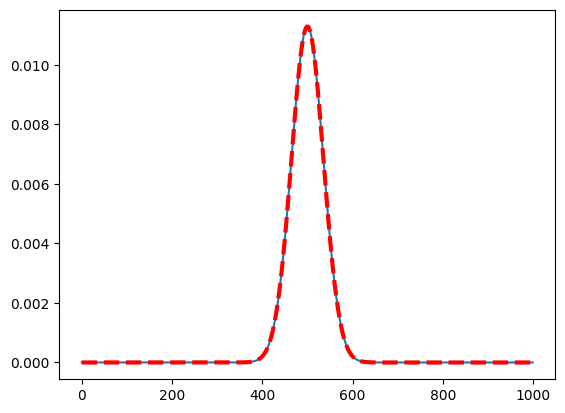

In [106]:
#b,c = A.SHO_wvfn(0)
c, b = A.SHO_wvfn(0)
print(b.shape)

#D = V[:,0].reshape(M,N)

#print(D.shape)

plt.plot(abs(V[:,0])**2)
plt.plot( abs(b)**2, linestyle='dashed',color='red', lw=3)

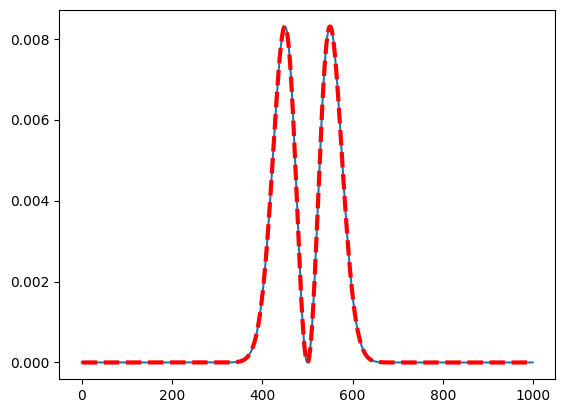

In [107]:
c, b = A.SHO_wvfn(1)

plt.plot(abs(V[:,1])**2)
plt.plot( abs(b)**2, linestyle='dashed',color='red', lw=3)

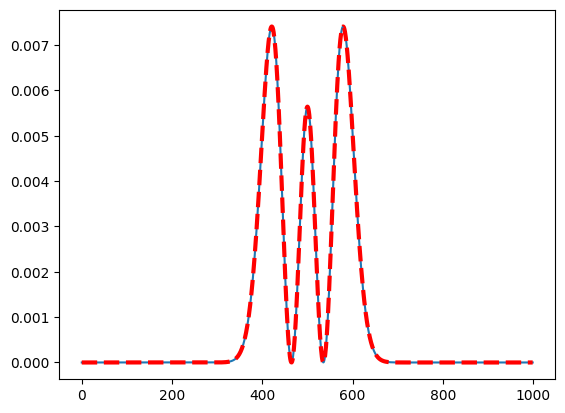

In [108]:
c, b = A.SHO_wvfn(2)

plt.plot( abs(V[:,2])**2)
plt.plot(  abs(b)**2, linestyle='dashed',color='red', lw=3)

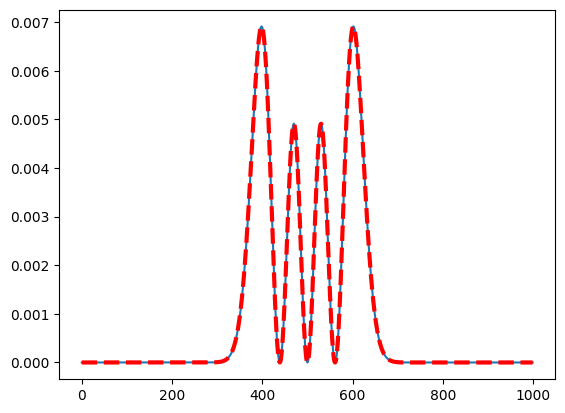

In [109]:
b,c = A.SHO_wvfn(3)

plt.plot( abs(V[:,3])**2)
plt.plot(  abs(c)**2, linestyle='dashed',color='red', lw=3)

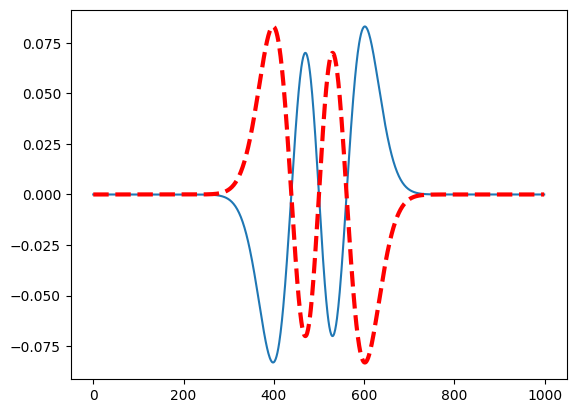

In [110]:
d, b = A.SHO_wvfn(3)

#d = A.ysq_matrix().toarray()

plt.plot( (V[:,3]))
plt.plot(  -(b), linestyle='dashed',color='red', lw=3)

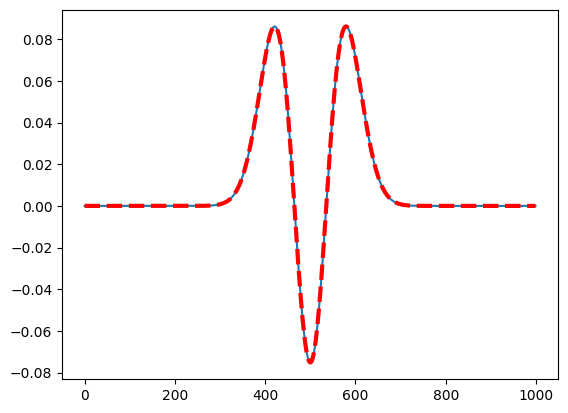

In [111]:
b,c = A.SHO_wvfn(2)

plt.plot( (V[:,2]))
plt.plot(  c, linestyle='dashed',color='red', lw=3)

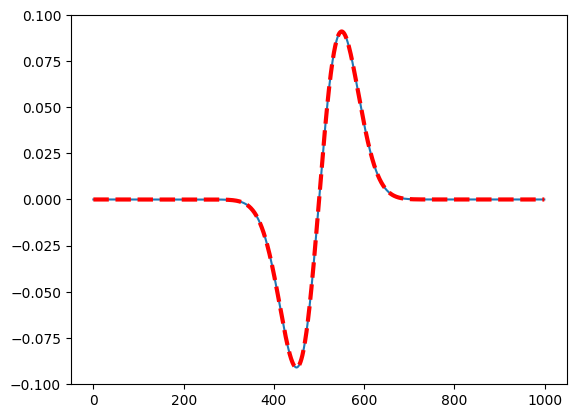

In [112]:
c,b = A.SHO_wvfn(1)

plt.plot( (V[:,1]))
plt.plot(  (b), linestyle='dashed',color='red', lw=3)

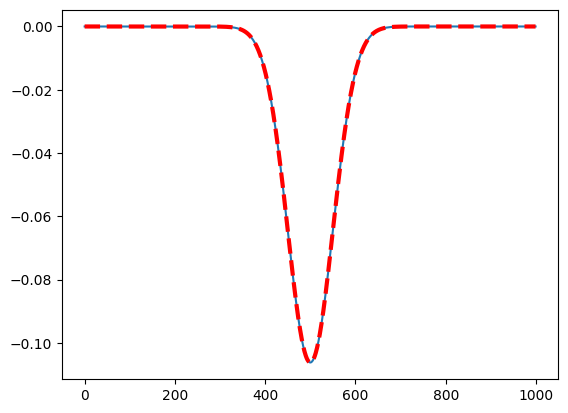

In [113]:
c, b = A.SHO_wvfn(0)

plt.plot( (V[:,0]))
plt.plot( -b, linestyle='dashed',color='red', lw=3)

checkin Udag matrix

In [127]:
N = 1
NSM = 1 
NSC = 1            ### DOESNT' MATTER WHAT WE PTU N, NSSC, NSM AS ATLEAST FOR THIS NOTEBOOK  
M = 100 
AX = 1
AY = 1 
LY = (M//10)*AY

MEFF_SC = 1 

OMEGA =  2*4*hbm/LY**2/MEFF_SC

KNUM= 8 

A = twoD_Minimal_Model(N,NSM,NSC,M,AX,AY,OMEGA)

H = A.SHO_Hamiltonian_in_y()

E, V = eigsh(H , k = KNUM, sigma=0 )

print(E)

print(V.shape)

[ 1.52147279  4.55673381  7.5765663  10.58084987 13.56946094 16.5422726
 19.49915448 22.43997259]
(100, 8)


In [ ]:
U = A.U_dag(1000)@H@A.U_dag().conjugate().transpose()

In [122]:
ud = A.U_dag(10)
u = A.U_dag(10).conjugate().transpose()

In [123]:
W = ud.dot(H).dot(u)

In [124]:
print(W.shape)

(10, 10)


In [126]:
print(W.diagonal())

[ 1.52149507  4.55690939  7.57722252 10.58253513 13.57294741 16.54855901
 19.50946912 22.4557764  25.38757902 28.30497468]
